<a href="https://colab.research.google.com/github/Kowsika0789/DL-unit-test2-/blob/main/DL_test.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np

df = pd.read_csv("/content/dataset.csv")

print("Dataset shape:", df.shape)
print("\nColumn names:", df.columns.tolist())
print("\nFirst 5 rows:")

display(df.head())

Dataset shape: (22000, 2)

Column names: ['Text', 'language']

First 5 rows:


,Text,language
0,klement gottwaldi surnukeha palsameeriti ning ...,Estonian
1,sebes joseph pereira thomas på eng the jesuit...,Swedish
2,ถนนเจริญกรุง อักษรโรมัน thanon charoen krung เ...,Thai
3,விசாகப்பட்டினம் தமிழ்ச்சங்கத்தை இந்துப் பத்திர...,Tamil
4,de spons behoort tot het geslacht haliclona en...,Dutch


In [ ]:

print("Missing values before cleaning:")
print(df.isnull().sum())

df = df.dropna(subset=["Text", "language"])

df["Text"] = df["Text"].astype(str).str.strip()
df["language"] = df["language"].astype(str).str.strip()

df = df[
    (df["Text"] != "") &
    (df["language"] != "")
]

df = df.drop_duplicates()

df = df.reset_index(drop=True)

print("\nDataset shape after cleaning:", df.shape)
print("\nNumber of languages:", df["language"].nunique())
print("\nSamples per language:")
print(df["language"].value_counts())

display(df.head())


Missing values before cleaning:
Text        0
language    0
dtype: int64

Dataset shape after cleaning: (21858, 2)

Number of languages: 22

Samples per language:
language
Japanese      1000
Thai          1000
Korean        1000
Chinese       1000
Urdu          1000
Turkish       1000
Romanian      1000
English       1000
Persian       1000
Estonian       999
Russian        999
Arabic         998
Portugese      997
Spanish        996
Dutch          995
Pushto         993
Swedish        992
French         990
Hindi          990
Tamil          981
Indonesian     975
Latin          953
Name: count, dtype: int64


,Text,language
0,klement gottwaldi surnukeha palsameeriti ning ...,Estonian
1,sebes joseph pereira thomas på eng the jesuit...,Swedish
2,ถนนเจริญกรุง อักษรโรมัน thanon charoen krung เ...,Thai
3,விசாகப்பட்டினம் தமிழ்ச்சங்கத்தை இந்துப் பத்திர...,Tamil
4,de spons behoort tot het geslacht haliclona en...,Dutch


In [ ]:

print("Samples per language before selection:")
print(df["language"].value_counts())

df = (
    df.groupby("language", group_keys=False)
      .apply(lambda x: x.sample(
          n=min(len(x), 500),
          random_state=42
      ))
      .reset_index(drop=True)
)

print("\nDataset shape after selection:", df.shape)
print("Number of languages:", df["language"].nunique())
print("\nSamples per language:")
print(df["language"].value_counts())


Samples per language before selection:
language
Japanese      1000
Thai          1000
Korean        1000
Chinese       1000
Urdu          1000
Turkish       1000
Romanian      1000
English       1000
Persian       1000
Estonian       999
Russian        999
Arabic         998
Portugese      997
Spanish        996
Dutch          995
Pushto         993
Swedish        992
French         990
Hindi          990
Tamil          981
Indonesian     975
Latin          953
Name: count, dtype: int64

Dataset shape after selection: (11000, 2)
Number of languages: 22

Samples per language:
language
Arabic        500
Chinese       500
Dutch         500
English       500
Estonian      500
French        500
Hindi         500
Indonesian    500
Japanese      500
Korean        500
Latin         500
Persian       500
Portugese     500
Pushto        500
Romanian      500
Russian       500
Spanish       500
Swedish       500
Tamil         500
Thai          500
Turkish       500
Urdu          500
Name: count, 

/tmp/ipykernel_2138/1523195972.py:8: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda x: x.sample(


In [ ]:

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

# Input text and target language
X = df["Text"].values
y = df["language"].values

# Split: 70% training, 30% temporary
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

# Split remaining data equally into validation and test
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

# Convert language names into numeric labels
label_encoder = LabelEncoder()

y_train = label_encoder.fit_transform(y_train)
y_val = label_encoder.transform(y_val)
y_test = label_encoder.transform(y_test)

NUM_CLASSES = len(label_encoder.classes_)

print("Training samples:", len(X_train))
print("Validation samples:", len(X_val))
print("Testing samples:", len(X_test))
print("Number of languages:", NUM_CLASSES)

print("\nLanguage labels:")
for i, language in enumerate(label_encoder.classes_):
    print(i, "=", language)


Training samples: 7700
Validation samples: 1650
Testing samples: 1650
Number of languages: 22

Language labels:
0 = Arabic
1 = Chinese
2 = Dutch
3 = English
4 = Estonian
5 = French
6 = Hindi
7 = Indonesian
8 = Japanese
9 = Korean
10 = Latin
11 = Persian
12 = Portugese
13 = Pushto
14 = Romanian
15 = Russian
16 = Spanish
17 = Swedish
18 = Tamil
19 = Thai
20 = Turkish
21 = Urdu


In [ ]:

from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

# Maximum sequence length
MAX_LEN = 300

# Create a character-level tokenizer
tokenizer = Tokenizer(
    char_level=True,
    lower=False,
    filters="",
    oov_token="<OOV>"
)

# Learn the character vocabulary from training data
tokenizer.fit_on_texts(X_train)

# Convert text into numerical sequences
X_train_seq = tokenizer.texts_to_sequences(X_train)
X_val_seq = tokenizer.texts_to_sequences(X_val)
X_test_seq = tokenizer.texts_to_sequences(X_test)

# Pad all sequences to the same length
X_train_pad = pad_sequences(
    X_train_seq,
    maxlen=MAX_LEN,
    padding="post",
    truncating="post"
)

X_val_pad = pad_sequences(
    X_val_seq,
    maxlen=MAX_LEN,
    padding="post",
    truncating="post"
)

X_test_pad = pad_sequences(
    X_test_seq,
    maxlen=MAX_LEN,
    padding="post",
    truncating="post"
)

# Vocabulary size
VOCAB_SIZE = len(tokenizer.word_index) + 1

print("Vocabulary size:", VOCAB_SIZE)
print("Training shape:", X_train_pad.shape)
print("Validation shape:", X_val_pad.shape)
print("Testing shape:", X_test_pad.shape)

print("\nOriginal text:", X_train[0])
print("Numerical sequence:", X_train_seq[0][:30])


Vocabulary size: 5734
Training shape: (7700, 300)
Validation shape: (1650, 300)
Testing shape: (1650, 300)

Original text: dave matthews  friends performed occasional shows again in   and  in  reynolds joined dave matthews band on their summer north american tour and scheduled to rejoin them on their spring  north american tour
Numerical sequence: [13, 4, 33, 3, 2, 15, 4, 8, 8, 26, 3, 66, 9, 2, 2, 37, 7, 5, 3, 6, 13, 9, 2, 19, 3, 7, 37, 10, 7, 15]


In [ ]:

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Input,
    Embedding,
    LSTM,
    Dropout,
    Dense
)

# Set random seed for reproducibility
tf.keras.utils.set_random_seed(42)

# Build the model
model = Sequential([
    Input(shape=(MAX_LEN,)),

    # Convert character IDs into vectors
    Embedding(
        input_dim=VOCAB_SIZE,
        output_dim=64,
        mask_zero=True
    ),

    # First LSTM layer
    LSTM(128, return_sequences=True),

    Dropout(0.3),

    # Second LSTM layer
    LSTM(64),

    Dropout(0.3),

    # Classification layer
    Dense(64, activation="relu"),

    # Output layer: one class per language
    Dense(NUM_CLASSES, activation="softmax")
])

# Compile the model
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# Display the model architecture
model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 300, 64)        │       366,976 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 300, 128)       │        98,816 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 300, 128)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 64)             │        49,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 22)             │         1,430 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 520,790 (1.99 MB)

 Trainable params: 520,790 (1.99 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:

history = model.fit(
    X_train_pad,
    y_train,
    validation_data=(X_val_pad, y_val),
    epochs=10,
    batch_size=64,
    verbose=1
)


Epoch 1/10
121/121 ━━━━━━━━━━━━━━━━━━━━ 11s 34ms/step - accuracy: 0.1816 - loss: 2.4379 - val_accuracy: 0.2945 - val_loss: 1.8434
Epoch 2/10
121/121 ━━━━━━━━━━━━━━━━━━━━ 3s 28ms/step - accuracy: 0.3940 - loss: 1.6840 - val_accuracy: 0.4976 - val_loss: 1.4386
Epoch 3/10
121/121 ━━━━━━━━━━━━━━━━━━━━ 3s 28ms/step - accuracy: 0.5013 - loss: 1.4217 - val_accuracy: 0.5485 - val_loss: 1.2234
Epoch 4/10
121/121 ━━━━━━━━━━━━━━━━━━━━ 3s 28ms/step - accuracy: 0.4813 - loss: 1.4863 - val_accuracy: 0.5782 - val_loss: 1.1318
Epoch 5/10
121/121 ━━━━━━━━━━━━━━━━━━━━ 3s 28ms/step - accuracy: 0.5383 - loss: 1.2972 - val_accuracy: 0.5188 - val_loss: 1.2705
Epoch 6/10
121/121 ━━━━━━━━━━━━━━━━━━━━ 4s 29ms/step - accuracy: 0.5609 - loss: 1.1843 - val_accuracy: 0.5461 - val_loss: 1.1667
Epoch 7/10
121/121 ━━━━━━━━━━━━━━━━━━━━ 3s 28ms/step - accuracy: 0.6078 - loss: 1.0430 - val_accuracy: 0.6321 - val_loss: 0.9660
Epoch 8/10
121/121 ━━━━━━━━━━━━━━━━━━━━ 5s 28ms/step - accuracy: 0.6030 - loss: 1.0572 - val_acc

In [ ]:

import numpy as np
import pandas as pd

# Check how many samples each language has
print("Samples per language:")
print(df["language"].value_counts().to_string())

# Check the length of text samples
text_lengths = df["Text"].astype(str).str.len()

print("\nText length statistics:")
print(text_lengths.describe(
    percentiles=[0.50, 0.75, 0.90, 0.95, 0.99]
))

# Check the current training and validation results
print("\nLast epoch results:")
for key, values in history.history.items():
    print(f"{key}: {values[-1]:.4f}")

# Check a few examples
display(df[["Text", "language"]].sample(
    min(10, len(df)), random_state=42
))


Samples per language:
language
Arabic        500
Chinese       500
Dutch         500
English       500
Estonian      500
French        500
Hindi         500
Indonesian    500
Japanese      500
Korean        500
Latin         500
Persian       500
Portugese     500
Pushto        500
Romanian      500
Russian       500
Spanish       500
Swedish       500
Tamil         500
Thai          500
Turkish       500
Urdu          500

Text length statistics:
count    11000.000000
mean       355.108545
std        237.929532
min         13.000000
50%        274.000000
75%        440.000000
90%        666.000000
95%        879.000000
99%       1201.020000
max       1335.000000
Name: Text, dtype: float64

Last epoch results:
accuracy: 0.5873
loss: 1.1205
val_accuracy: 0.5776
val_loss: 1.1522


,Text,language
107,ماوريسيو سيرنا مواليد يناير -- هو لاعب كرة قد...,Arabic
5484,rupt est commune francicum incolarum anno pr...,Latin
6998,دکلورين په کارولو سره اوبه دمکروبونو نه پاکيږي...,Pushto
3984,latrunculia biannulata microacanthoxea adalah ...,Indonesian
3111,ताप संपीड़न एक और प्रक्रिया है जो नई कंपनियों ...,Hindi
4040,年、地質学者トーマス・ライト（en）はワイト島のブリックストン近郊のウィールデン・クレイで発...,Japanese
3013,वैश्वानर तेजस और प्राज्ञ अवस्थाओं के सदृश त्रै...,Hindi
6607,خپلې لومړنۍ او د لېسې زده کړې یې د رابعې بلخي ...,Pushto
4219,月日に美浦トレーニングセンターに帰厩し、月日のきんせんか賞（万下）で実戦復帰を果たした。レー...,Japanese
8750,terrängen runt third lake rip är platt den hög...,Swedish


In [ ]:

from tensorflow.keras.callbacks import (
    ReduceLROnPlateau,
    ModelCheckpoint
)

callbacks = [
    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=0.00001,
        verbose=1
    ),

    ModelCheckpoint(
        filepath="/content/best_language_lstm.keras",
        monitor="val_accuracy",
        save_best_only=True,
        mode="max",
        verbose=1
    )
]


In [ ]:
history = model.fit(
    X_train_pad,
    y_train,
    validation_data=(X_val_pad, y_val),
    epochs=15,
    batch_size=64,
    callbacks=callbacks,
    verbose=1
)

Epoch 1/15
120/121 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - accuracy: 0.6066 - loss: 1.0227
Epoch 1: val_accuracy improved from None to 0.67515, saving model to /content/best_language_lstm.keras

Epoch 1: finished saving model to /content/best_language_lstm.keras
121/121 ━━━━━━━━━━━━━━━━━━━━ 4s 33ms/step - accuracy: 0.6245 - loss: 0.9597 - val_accuracy: 0.6752 - val_loss: 0.8170 - learning_rate: 0.0010
Epoch 2/15
119/121 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - accuracy: 0.6696 - loss: 0.8307
Epoch 2: val_accuracy did not improve from 0.67515
121/121 ━━━━━━━━━━━━━━━━━━━━ 3s 28ms/step - accuracy: 0.6710 - loss: 0.8228 - val_accuracy: 0.6636 - val_loss: 0.8529 - learning_rate: 0.0010
Epoch 3/15
119/121 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - accuracy: 0.6749 - loss: 0.8111
Epoch 3: val_accuracy improved from 0.67515 to 0.70000, saving model to /content/best_language_lstm.keras

Epoch 3: finished saving model to /content/best_language_lstm.keras
121/121 ━━━━━━━━━━━━━━━━━━━━ 4s 29ms/step - accuracy: 0.6

In [ ]:
import tensorflow as tf
import numpy as np

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# Load the best checkpoint
model = tf.keras.models.load_model(
    "/content/best_language_lstm.keras"
)

# Predict on the untouched test set
y_prob = model.predict(X_test_pad, verbose=0)
y_pred = np.argmax(y_prob, axis=1)

# Calculate evaluation metrics
print(f"Test Accuracy: {accuracy_score(y_test, y_pred) * 100:.2f}%")

print(f"Precision (macro): {precision_score(y_test, y_pred, average='macro', zero_division=0):.4f}")
print(f"Recall (macro):    {recall_score(y_test, y_pred, average='macro', zero_division=0):.4f}")
print(f"F1-score (macro):  {f1_score(y_test, y_pred, average='macro', zero_division=0):.4f}")

print("\nDetailed report:\n")
print(classification_report(
    y_test,
    y_pred,
    target_names=label_encoder.classes_,
    zero_division=0
))

Test Accuracy: 82.67%
Precision (macro): 0.8507
Recall (macro):    0.8267
F1-score (macro):  0.8139

Detailed report:

              precision    recall  f1-score   support

      Arabic       0.99      0.99      0.99        75
     Chinese       0.99      0.96      0.97        75
       Dutch       0.46      0.41      0.44        75
     English       0.38      0.79      0.51        75
    Estonian       0.77      0.87      0.82        75
      French       0.76      0.64      0.70        75
       Hindi       1.00      0.99      0.99        75
  Indonesian       0.81      0.97      0.88        75
    Japanese       0.96      1.00      0.98        75
      Korean       1.00      1.00      1.00        75
       Latin       0.67      0.05      0.10        75
     Persian       0.97      1.00      0.99        75
   Portugese       0.46      0.84      0.60        75
      Pushto       1.00      0.89      0.94        75
    Romanian       0.91      0.91      0.91        75
     Russian    

TESTING RESULTS
----------------
Total test samples: 1650
Correct predictions: 1364
Incorrect predictions: 286
Testing accuracy: 82.67%


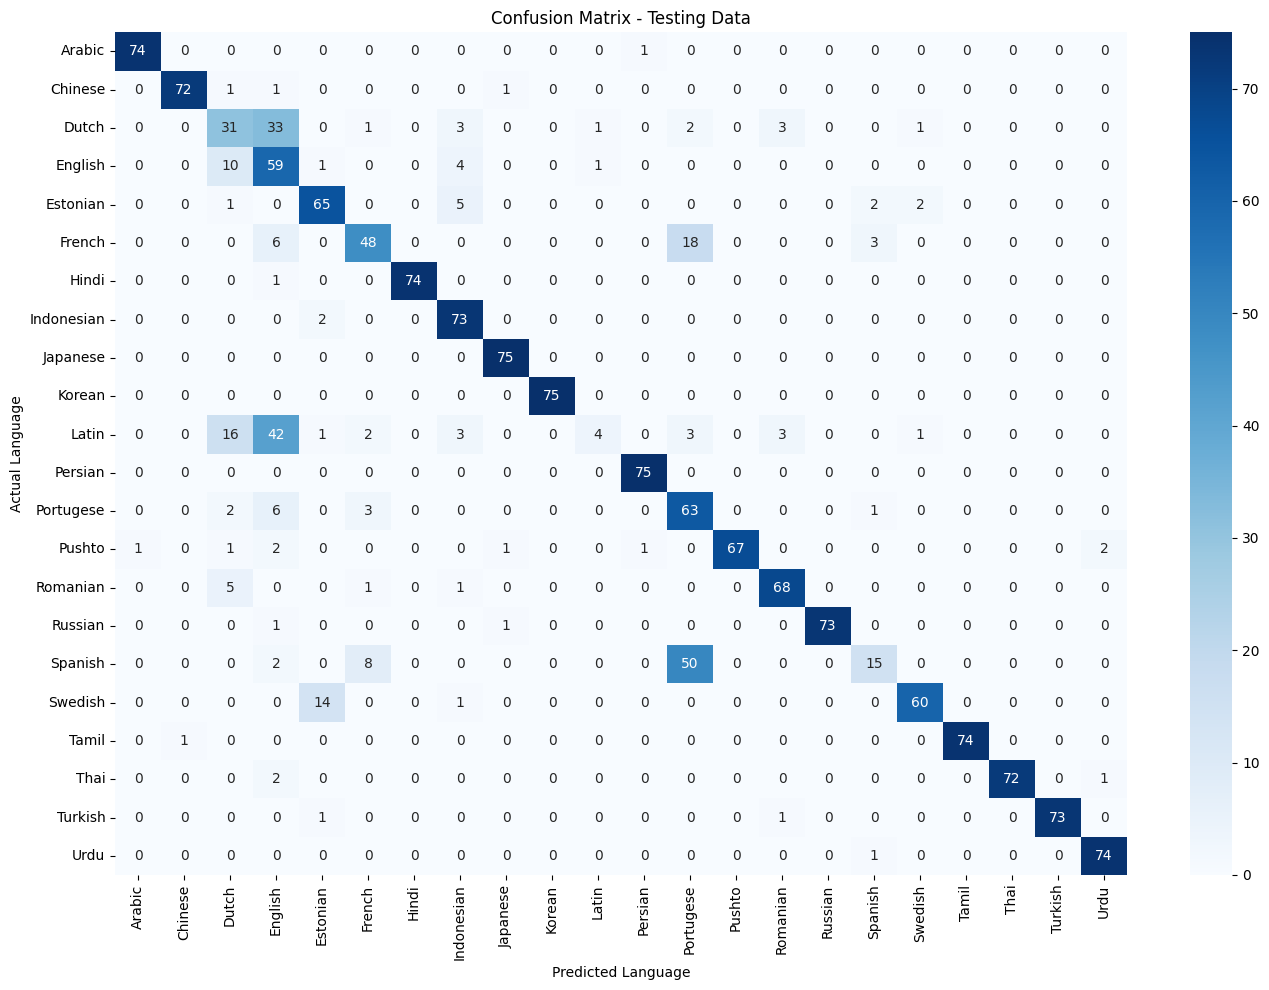

In [ ]:

from sklearn.metrics import accuracy_score, confusion_matrix
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Predict using the unseen test data
y_prob = model.predict(X_test_pad, verbose=0)
y_pred = np.argmax(y_prob, axis=1)

# Compare actual and predicted labels
correct = np.sum(y_pred == y_test)
incorrect = np.sum(y_pred != y_test)

print("TESTING RESULTS")
print("----------------")
print("Total test samples:", len(y_test))
print("Correct predictions:", correct)
print("Incorrect predictions:", incorrect)
print(f"Testing accuracy: {accuracy_score(y_test, y_pred) * 100:.2f}%")

# Display confusion matrix
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(14, 10))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)
plt.xlabel("Predicted Language")
plt.ylabel("Actual Language")
plt.title("Confusion Matrix - Testing Data")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


In [ ]:

import numpy as np
from tensorflow.keras.preprocessing.sequence import pad_sequences

def predict_language(text):
    if not text.strip():
        print("Please enter some text.")
        return

    # Convert the input text into numbers
    sequence = tokenizer.texts_to_sequences([text])

    # Pad the sequence to the model's required length
    padded_text = pad_sequences(
        sequence,
        maxlen=MAX_LEN,
        padding="post",
        truncating="post"
    )

    # Predict the language
    probabilities = model.predict(padded_text, verbose=0)[0]
    predicted_index = int(np.argmax(probabilities))
    predicted_language = label_encoder.inverse_transform(
        [predicted_index]
    )[0]

    print("Input text:", text)
    print("Predicted language:", predicted_language)
    print(f"Model confidence: {probabilities[predicted_index] * 100:.2f}%")

    # Display the top 3 predictions
    top_indices = np.argsort(probabilities)[-3:][::-1]

    print("\nTop 3 predictions:")
    for index in top_indices:
        language = label_encoder.inverse_transform([int(index)])[0]
        print(f"{language}: {probabilities[index] * 100:.2f}%")

text = input("Enter a text sample: ")
predict_language(text)


Enter a text sample: Tere! Kuidas sul täna läheb? Ma õpin uusi keeli.
Input text: Tere! Kuidas sul täna läheb? Ma õpin uusi keeli.
Predicted language: Estonian
Model confidence: 79.46%

Top 3 predictions:
Estonian: 79.46%
Swedish: 18.54%
Indonesian: 1.03%


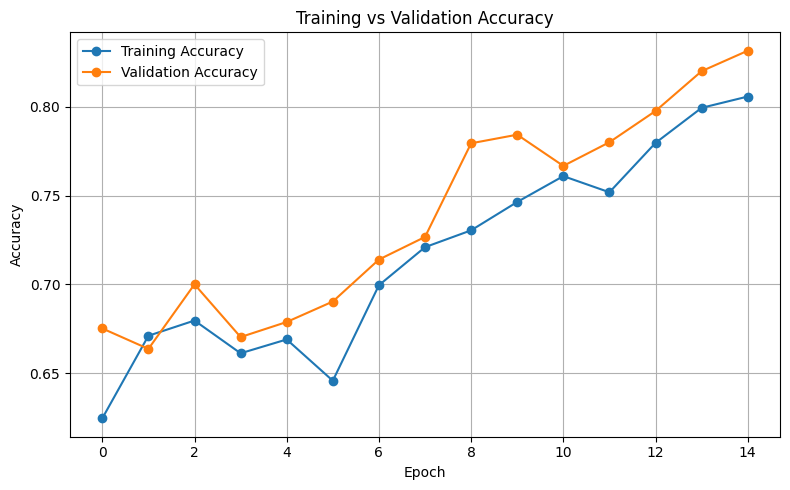

In [ ]:

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(history.history["accuracy"], marker="o", label="Training Accuracy")
plt.plot(history.history["val_accuracy"], marker="o", label="Validation Accuracy")

plt.title("Training vs Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


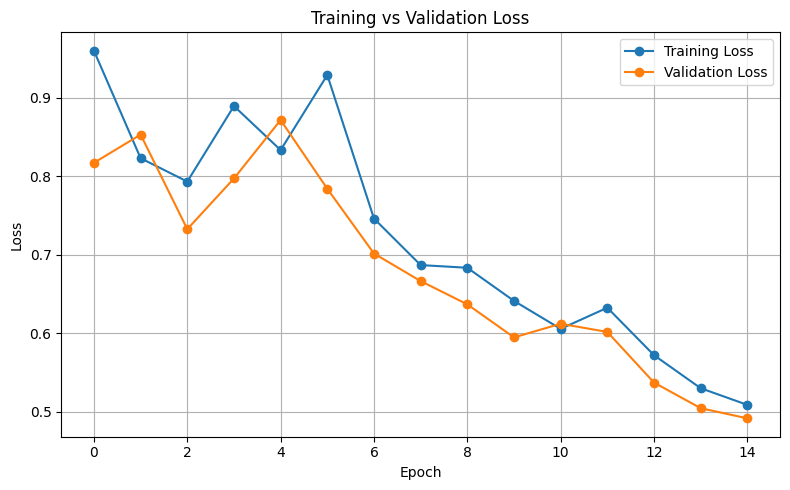

In [ ]:

plt.figure(figsize=(8, 5))

plt.plot(history.history["loss"], marker="o", label="Training Loss")
plt.plot(history.history["val_loss"], marker="o", label="Validation Loss")

plt.title("Training vs Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


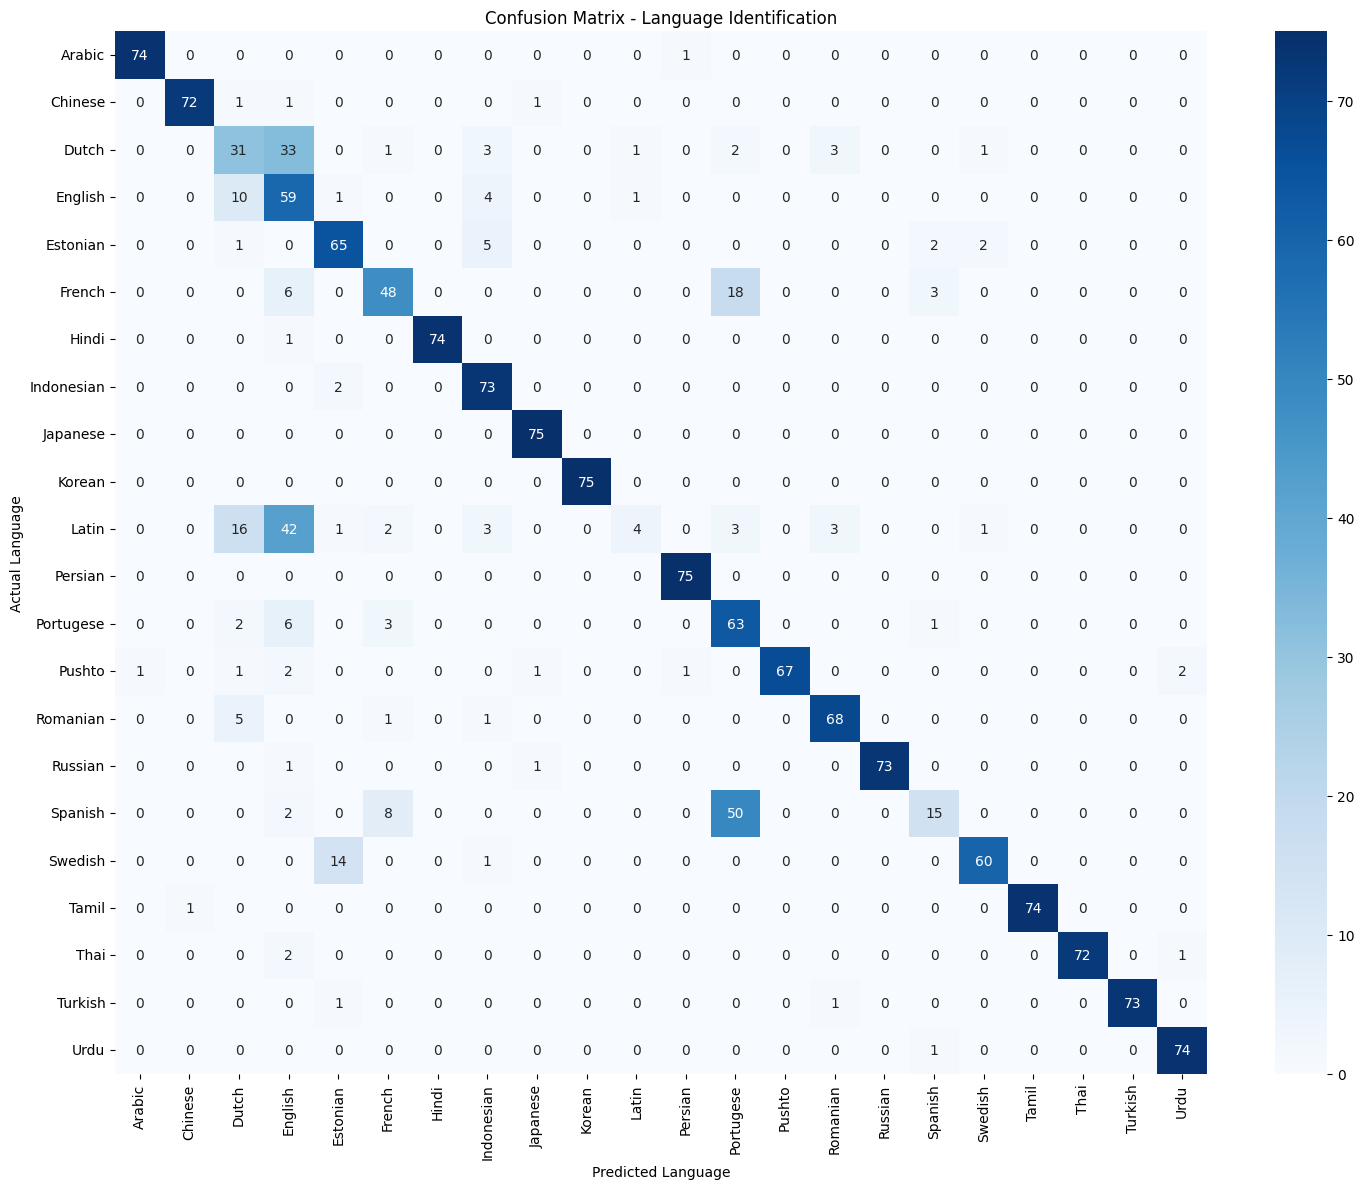

In [ ]:

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Use the best saved model and test data
y_prob = model.predict(X_test_pad, verbose=0)
y_pred = np.argmax(y_prob, axis=1)

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=np.arange(len(label_encoder.classes_))
)

plt.figure(figsize=(15, 12))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

plt.title("Confusion Matrix - Language Identification")
plt.xlabel("Predicted Language")
plt.ylabel("Actual Language")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()
